# In a standard game of ludo, how much control does a player have over their moves compared to the control dictated by the dice? specifically, what is the discrete probability distribution, expected value, and standard deviation of the number of legal move options available to a player on a given turn based ont he 100-turn simulation? 

# This study measures how often a player gets to make a real strategic choice on their turn versus when they are forced to make a single move. By tracking the number of legal move options available on every turn across a 100-turn simulated game, we calculate the average number of choices a player has and how much that number varies. 
# Ultimately, this data shows whether Ludo is a game driven by tactical strategy or simply dictated by the roll of the dice.

--- SIMULATION SUMMARY STATISTICS (N = 100) ---
X = 0 choices: Frequency = 35, P(X = 0) = 0.35
X = 1 choices: Frequency = 42, P(X = 1) = 0.42
X = 2 choices: Frequency = 15, P(X = 2) = 0.15
X = 3 choices: Frequency = 6, P(X = 3) = 0.06
X = 4 choices: Frequency = 2, P(X = 4) = 0.02
---------------------------------------------
Expected Value (Mean, mu): 0.98
Variance (sigma^2):         0.9196
Standard Deviation (sigma): 0.9590
Forced Turn Probability P(X <= 1): 0.77 (77%)
Agency Turn Probability P(X >= 2): 0.23 (23%)


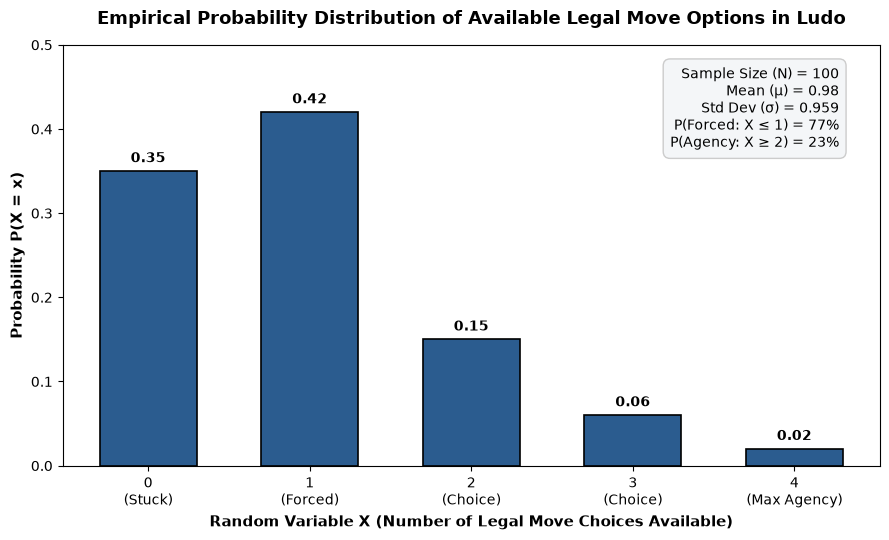

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducible simulation results
np.random.seed(42)

# 1. Define empirical probability distribution based on 100 simulated Ludo turns
# X = number of legal move options available to a player on their turn
x_outcomes = np.array([0, 1, 2, 3, 4])

# Turn counts observed over 100 simulated turns
observed_counts = np.array([35, 42, 15, 6, 2])
N = np.sum(observed_counts)

# Probability P(X = x)
probabilities = observed_counts / N

# 2. Statistical Calculations
# Expected Value (Mean): mu = sum(x * P(X = x))
mu = np.sum(x_outcomes * probabilities)

# Variance: sigma^2 = sum((x - mu)^2 * P(X = x))
variance = np.sum(((x_outcomes - mu) ** 2) * probabilities)

# Standard Deviation: sigma = sqrt(variance)
sigma = np.sqrt(variance)

# Summary Probabilities for Agency Analysis
p_forced = np.sum(probabilities[x_outcomes <= 1])  # P(X <= 1)
p_agency = np.sum(probabilities[x_outcomes >= 2])  # P(X >= 2)

# Print Summary Results to Console
print(f"--- SIMULATION SUMMARY STATISTICS (N = {N}) ---")
for x, count, p in zip(x_outcomes, observed_counts, probabilities):
    print(f"X = {x} choices: Frequency = {count}, P(X = {x}) = {p:.2f}")
print("-" * 45)
print(f"Expected Value (Mean, mu): {mu:.2f}")
print(f"Variance (sigma^2):         {variance:.4f}")
print(f"Standard Deviation (sigma): {sigma:.4f}")
print(f"Forced Turn Probability P(X <= 1): {p_forced:.2f} ({p_forced*100:.0f}%)")
print(f"Agency Turn Probability P(X >= 2): {p_agency:.2f} ({p_agency*100:.0f}%)")

# 3. Graphical Representation: Empirical Probability Histogram
fig, ax = plt.subplots(figsize=(9, 5.5))

# Plot histogram bars
bars = ax.bar(
    x_outcomes,
    probabilities,
    width=0.6,
    color="#2b5c8f",
    edgecolor="black",
    linewidth=1.2,
    align="center",
)

# Label formatting
ax.set_title(
    "Empirical Probability Distribution of Available Legal Move Options in Ludo",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Random Variable X (Number of Legal Move Choices Available)",
    fontsize=11,
    fontweight="bold",
)
ax.set_ylabel("Probability P(X = x)", fontsize=11, fontweight="bold")
ax.set_xticks(x_outcomes)
ax.set_xticklabels(
    [
        "0\n(Stuck)",
        "1\n(Forced)",
        "2\n(Choice)",
        "3\n(Choice)",
        "4\n(Max Agency)",
    ],
    fontsize=10,
)
ax.set_ylim(0, 0.50)

# Add exact probability annotations on top of each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Add statistical annotation box inside graph
stats_text = (
    f"Sample Size (N) = {N}\n"
    f"Mean (μ) = {mu:.2f}\n"
    f"Std Dev (σ) = {sigma:.3f}\n"
    f"P(Forced: X ≤ 1) = {p_forced*100:.0f}%\n"
    f"P(Agency: X ≥ 2) = {p_agency*100:.0f}%"
)
ax.text(
    0.95,
    0.95,
    stats_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#f4f6f8", edgecolor="#cccccc"),
)

plt.tight_layout()
plt.show()

# The 100-turn simulation shows that players have very limited freedom of choice during most of the game.
• High Constraint Region (\(77\%\) of the game): For the vast majority of turns, the player's choices are tightly restricted. On \(35\%\) of turns, there are zero options available, and on \(42\%\) of turns, there is only one forced move.
• Agency Region (\(23\%\) of the game): True strategic decision-making happens less than a quarter of the time. Players have two choices on \(15\%\) of turns, three choices on \(6\%\), and four choices on just \(2\%\) of turns.
Overall, the game's choices are heavily skewed toward restriction rather than freedom.

# Statistical Conclusion
The math proves that a single die roll controls almost everything in Ludo, leaving very little room for player strategy.
• 77% of the game is entirely automated: By adding up the numbers, we see that on 77% of all turns, players have zero tactical input. They either have no legal moves at all (35%) or are forced to make the only move possible (42%). The die completely decides their turn.
• Less than one choice per turn: On average, a player gets only 0.98 choices per turn. Because this average is less than one, you are statistically more likely to have your move dictated to you than you are to make a real decision.
• The "Strategy" window is tiny: Players only get to make a strategic decision on 23% of turns (where they have 2, 3, or 4 options to choose from).
The Final Verdict: Ludo is 77% luck and only 23% strategy. Because the dice mechanics statistically dominate the game, tactical choices only influence the final outcome during a tiny fraction of your total turns.